# Ames Housing: Ridge ve Lasso Regresyon Projesi
## Bölüm 1: Veriyi Tanıma (Adım 1)

Bu defter projenin ilk bölümüdür. Amaç, modele geçmeden önce verinin nereden geldiğini,
neleri içerdiğini ve hedef değişkenin nasıl davrandığını anlamaktır.

**Önemli kural:** Test verisine proje sonuna kadar bakılmayacak. Bu yüzden veriyi en başta
eğitim ve test olarak ayırıp, **keşif grafiklerini yalnızca eğitim kısmıyla** çiziyoruz.
Böylece test verisinden hiçbir bilgi sızmaz (veri sızıntısı olmaz).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42   # tüm ekip aynı değeri kullanmalı
TARGET = "SalePrice"

### 1.1 Veriyi okuma

Ames veri setinde bazı sütunlarda `NA` yazısı "bu özellik yok" anlamına gelir
(ör. `Pool QC = NA` demek evde havuz olmadığıdır). Pandas bu yazıyı varsayılan olarak
*eksik veri* sayar ve bu yanlış olur. Bu yüzden `keep_default_na=False` ile okuyup,
yalnızca **gerçekten boş** hücreleri eksik sayıyoruz.

In [2]:
import os
for p in ["AmesHousing.csv", "/mnt/user-data/uploads/AmesHousing_1.csv"]:
    if os.path.exists(p):
        DATA_PATH = p
        break
else:
    raise FileNotFoundError("AmesHousing.csv bulunamadı. Dosyayı defterle aynı klasöre koyun.")

df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])
print("Dosya:", DATA_PATH)
print("Boyut (satır, sütun):", df.shape)
df.head(3).T.head(12)

Dosya: /mnt/user-data/uploads/AmesHousing_1.csv
Boyut (satır, sütun): (2930, 82)


,0,1,2
Order,1,2,3
PID,526301100,526350040,526351010
MS SubClass,20,20,20
MS Zoning,RL,RH,RL
Lot Frontage,141.0,80.0,81.0
Lot Area,31770,11622,14267
Street,Pave,Pave,Pave
Alley,NA,NA,NA
Lot Shape,IR1,Reg,IR1
Land Contour,Lvl,Lvl,Lvl


### 1.2 Kaynak ve genel bilgi

- **Kaynak:** Ames Housing veri seti. Dean De Cock tarafından 2011'de, Ames (Iowa, ABD) şehrinin
  konut satış kayıtlarından hazırlanmıştır (2006–2010 satışları).
- **Satır:** tek bir konutun satışı. **Hedef:** `SalePrice` (satış fiyatı, dolar).
- **Özellikler:** evin büyüklüğü, kalitesi, yaşı, konumu, garaj, bodrum, banyo vb.
- `Order` (sıra numarası) ve `PID` (parsel numarası) sadece **kimlik** sütunlarıdır.
  Fiyatla gerçek bir ilgileri yoktur, modelde kullanılmayacak.

In [3]:
ids = ["Order", "PID"]
df = df.drop(columns=ids)

n_num = df.drop(columns=TARGET).select_dtypes("number").shape[1]
n_cat = df.drop(columns=TARGET).select_dtypes(exclude="number").shape[1]
print(f"Satır: {len(df)}  |  Özellik: {df.shape[1]-1}  (sayısal {n_num}, kategorik {n_cat})")
print("Tekrar eden satır:", df.duplicated().sum())

Satır: 2930  |  Özellik: 79  (sayısal 36, kategorik 43)
Tekrar eden satır: 0


### 1.3 Eğitim / test ayrımı

Regresyon problemi olduğu için `stratify` kullanılmaz (o, sınıflandırma içindir).
%80 eğitim, %20 test. **Test kümesi bundan sonra kilitlidir.**

In [4]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print("Eğitim:", train_df.shape, " Test:", test_df.shape)

# Aynı ayrımın sonraki bölümlerde de kullanılması için kaydet
train_df.to_csv("ames_train.csv", index=False)
test_df.to_csv("ames_test.csv", index=False)

Eğitim: (2344, 80)  Test: (586, 80)


### 1.4 Sütunların anlamı (önemli gruplar)

| Grup | Örnek sütunlar | Anlamı |
|---|---|---|
| Konum | `Neighborhood`, `MS Zoning` | Mahalle ve imar bölgesi |
| Büyüklük | `Gr Liv Area`, `Lot Area`, `Total Bsmt SF`, `1st Flr SF` | Metrekare (ft²) değerleri |
| Kalite | `Overall Qual`, `Overall Cond`, `Kitchen Qual`, `Exter Qual` | 1–10 genel puan veya Ex/Gd/TA/Fa/Po |
| Yaş | `Year Built`, `Year Remod/Add`, `Yr Sold` | Yapım, tadilat ve satış yılı |
| Garaj | `Garage Type`, `Garage Cars`, `Garage Area` | Garaj bilgileri |
| Bodrum | `Bsmt Qual`, `Bsmt Exposure`, `BsmtFin SF 1` | Bodrum bilgileri |
| Banyo / oda | `Full Bath`, `Half Bath`, `Bedroom AbvGr`, `TotRms AbvGrd` | Sayılar |
| Ekstralar | `Pool QC`, `Fence`, `Fireplaces`, `Misc Feature` | Havuz, çit, şömine vb. |

Dikkat: `MS SubClass` sayı gibi görünür ama aslında bir **sınıf kodudur** (kategorik sayılmalı).

In [5]:
print("Veri tipleri:")
print(train_df.dtypes.value_counts().to_string())
print()
print("MS SubClass sayı olarak okundu ama kategoriktir. Farklı değer sayısı:", train_df["MS SubClass"].nunique())

Veri tipleri:
str        43
int64      26
float64    11

MS SubClass sayı olarak okundu ama kategoriktir. Farklı değer sayısı: 16


### 1.5 Eksik değerler: "yok" mu, gerçekten eksik mi?

Burada iki farklı durum vardır:

1. **`NA` yazısı (özellik yok):** havuz, çit, şömine, garaj, bodrum gibi sütunlarda evin o özelliğe
   sahip olmadığını gösterir. Bunlar eksik veri **değildir**, `"None"` kategorisi olarak ele alınacak.
2. **Boş hücre (gerçek eksik):** bilginin girilmemiş olduğu durumlar.

In [6]:
# 1) "NA" yazısı = özellik yok
na_text = {c: (train_df[c] == "NA").sum() for c in train_df.columns
           if train_df[c].dtype == object or str(train_df[c].dtype).startswith("str")}
na_text = pd.Series({k: v for k, v in na_text.items() if v > 0}).sort_values(ascending=False)
tbl1 = pd.DataFrame({"'NA' sayısı (özellik yok)": na_text,
                     "Oran (%)": (na_text / len(train_df) * 100).round(1)})
display(tbl1)

# 2) Gerçek eksik (boş hücre)
real = train_df.isna().sum()
real = real[real > 0].sort_values(ascending=False)
tbl2 = pd.DataFrame({"Gerçek eksik sayısı": real, "Oran (%)": (real / len(train_df) * 100).round(2)})
display(tbl2)

,'NA' sayısı (özellik yok),Oran (%)
Pool QC,2332,99.5
Misc Feature,2250,96.0
Alley,2182,93.1
Fence,1874,79.9
Fireplace Qu,1144,48.8
Garage Qual,121,5.2
Garage Cond,121,5.2
Garage Finish,120,5.1
Garage Type,120,5.1
BsmtFin Type 2,60,2.6


,Gerçek eksik sayısı,Oran (%)
Lot Frontage,393,16.77
Garage Yr Blt,122,5.20
Mas Vnr Area,19,0.81
Mas Vnr Type,19,0.81
Bsmt Exposure,3,0.13
Garage Finish,2,0.09
BsmtFin Type 2,2,0.09
Bsmt Qual,1,0.04
BsmtFin SF 1,1,0.04
BsmtFin SF 2,1,0.04


**Yorum:**
- `Pool QC`, `Misc Feature`, `Alley`, `Fence` sütunlarında verinin yaklaşık %80'i veya daha fazlası "yok" demektir.
  Bunları "var/yok" göstergesine çevirmek veya "None" kategorisi yapmak mantıklıdır.
- Gerçek eksiklerin büyüğü **`Lot Frontage`** (cadde cephesi uzunluğu). Burada boşluk "yok"
  anlamına gelmez, bilgi eksiktir. Doldurma stratejisi Adım 2'de (Pipeline içinde) seçilecek.
- `Garage Yr Blt` boşluğu (122 satır), büyük ölçüde garajı olmayan evlerle (120 satır) örtüşür:
  garaj yoksa garaj yılı da yoktur.
- `Mas Vnr Area/Type` (19 satır, %0,8) ve bodrum/garaj sütunlarındaki 1–3 satırlık boşluklar
  küçük kayıt eksikleridir, etkileri önemsizdir.

### 1.6 Hedef değişken: `SalePrice`

Sınıflandırmadaki "sınıf dengesi" yerine, regresyonda hedefin **dağılımına** bakılır. Dağılım çok
çarpıksa doğrusal modellerin varsayımları bozulur ve log dönüşümü gerekebilir.

count      2344.0
mean     178582.0
std       77125.0
min       12789.0
25%      129000.0
50%      160000.0
75%      210000.0
max      755000.0

Çarpıklık (skew), ham      : 1.751
Çarpıklık (skew), log(fiyat): -0.091


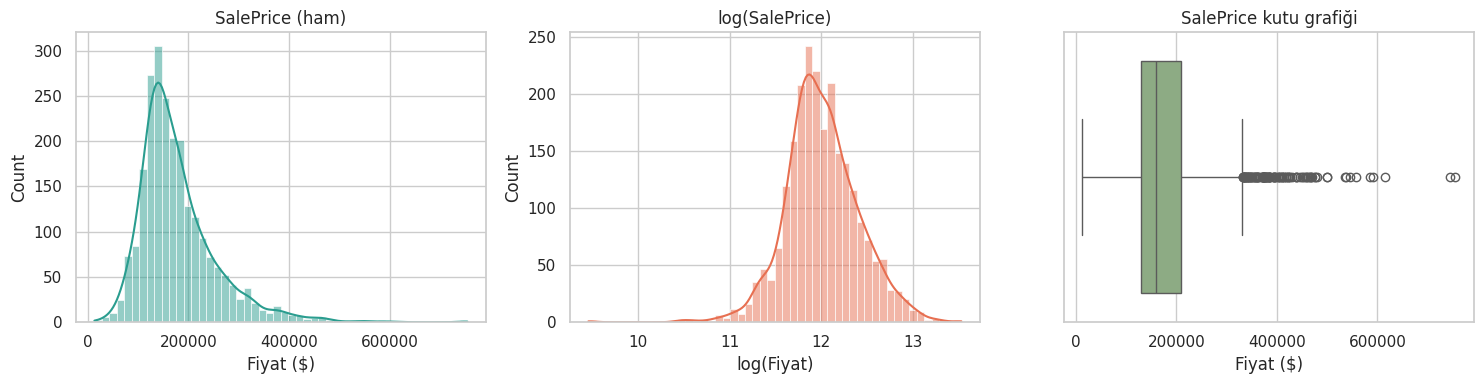

In [7]:
y = train_df[TARGET]
print(y.describe().round(0).to_string())
print()
print(f"Çarpıklık (skew), ham      : {y.skew():.3f}")
print(f"Çarpıklık (skew), log(fiyat): {np.log(y).skew():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(y, bins=50, kde=True, ax=ax[0], color="#2a9d8f")
ax[0].set_title("SalePrice (ham)"); ax[0].set_xlabel("Fiyat ($)")
sns.histplot(np.log(y), bins=50, kde=True, ax=ax[1], color="#e76f51")
ax[1].set_title("log(SalePrice)"); ax[1].set_xlabel("log(Fiyat)")
sns.boxplot(x=y, ax=ax[2], color="#8ab17d")
ax[2].set_title("SalePrice kutu grafiği"); ax[2].set_xlabel("Fiyat ($)")
plt.tight_layout(); plt.show()

**Yorum:** Fiyat belirgin şekilde **sağa çarpık** (az sayıda çok pahalı ev). Logaritması alınınca
dağılım neredeyse simetrik hale geliyor (çarpıklık ≈ 0). Bu, hedefin log dönüşümüyle modellenmesi
için güçlü bir gerekçedir. Ayrıca log ölçeğinde bir hata, "yüzde olarak hata" anlamına geldiği
için ucuz ve pahalı evlerin daha adil değerlendirilmesini sağlar.

### 1.7 Sayısal özelliklerin hedefle ilişkisi

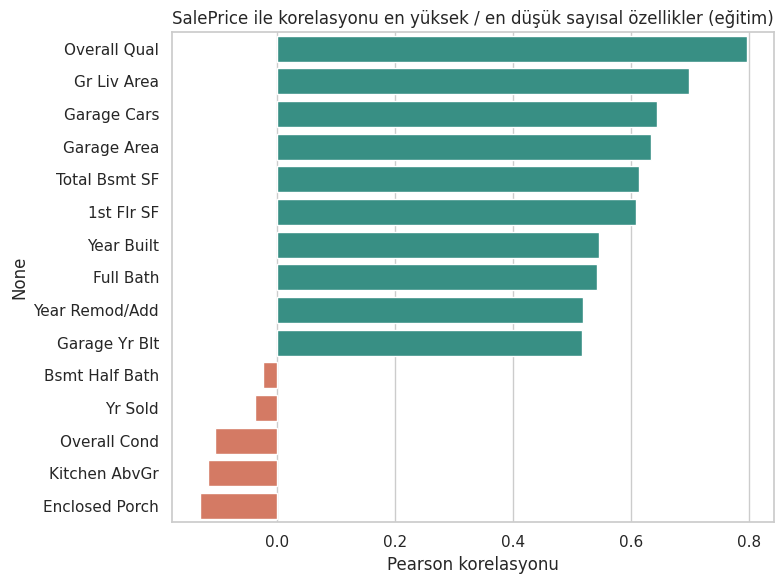

Overall Qual     0.795
Gr Liv Area      0.698
Garage Cars      0.644
Garage Area      0.633
Total Bsmt SF    0.612
1st Flr SF       0.607
Year Built       0.545
Full Bath        0.542


In [8]:
num_cols = train_df.select_dtypes("number").columns.drop(TARGET).drop("MS SubClass")
corr_t = train_df[num_cols].corrwith(train_df[TARGET]).sort_values(ascending=False)

top = pd.concat([corr_t.head(10), corr_t.tail(5)])
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, palette=["#2a9d8f" if v > 0 else "#e76f51" for v in top.values])
plt.title("SalePrice ile korelasyonu en yüksek / en düşük sayısal özellikler (eğitim)")
plt.xlabel("Pearson korelasyonu"); plt.tight_layout(); plt.show()
print(corr_t.head(8).round(3).to_string())

**Yorum:** Fiyatla en güçlü ilişki **`Overall Qual`** (genel kalite) ve **`Gr Liv Area`**
(yaşam alanı) sütunlarında. Ardından garaj ve bodrum büyüklüğü, banyo sayısı ve yapım yılı geliyor.

### 1.8 Özellikler arasındaki ilişki (çoklu doğrusal bağlantı)

Ridge ve Lasso'nun neden seçildiğinin gerekçesi burada görülür. Birbirine çok benzeyen özellikler
düz doğrusal regresyonda katsayıları kararsız yapar.

Korelasyonu 0.8'den büyük özellik çifti sayısı: 4


,,|korelasyon|
Garage Cars,Garage Area,0.884
Year Built,Garage Yr Blt,0.825
Total Bsmt SF,1st Flr SF,0.814
Gr Liv Area,TotRms AbvGrd,0.806


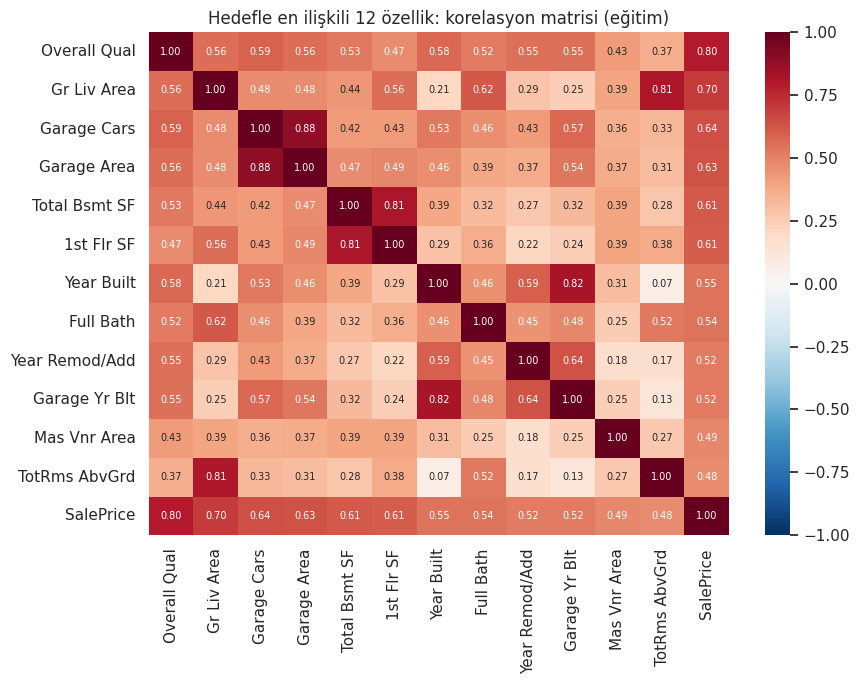

In [9]:
cm = train_df[num_cols].corr().abs()
pairs = (cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))
           .stack().sort_values(ascending=False))
high = pairs[pairs > 0.8]
print(f"Korelasyonu 0.8'den büyük özellik çifti sayısı: {len(high)}")
display(high.round(3).rename("|korelasyon|").to_frame())

top_feats = corr_t.abs().sort_values(ascending=False).head(12).index.tolist()
plt.figure(figsize=(9, 7))
sns.heatmap(train_df[top_feats + [TARGET]].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Hedefle en ilişkili 12 özellik: korelasyon matrisi (eğitim)")
plt.tight_layout(); plt.show()

**Yorum:** Özellikler birbirini yinelemektedir (örn. `Garage Cars` ile `Garage Area`,
`Gr Liv Area` ile `TotRms AbvGrd`, `1st Flr SF` ile `Total Bsmt SF`). Bu durumda düz doğrusal
regresyon hangi özelliğe ne kadar ağırlık vereceğini kararsız biçimde seçer. **Ridge** ağırlıkları
benzer özellikler arasında dengeler, **Lasso** ise bunlardan birini seçip diğerini sıfıra çekebilir.

### 1.9 Aykırı değer adayları

Bu veri setinin belgelerinde, çok büyük yaşam alanına rağmen çok düşük fiyata satılmış
birkaç evin modeli yanıltabileceği belirtilir. Grafikle kontrol edelim.

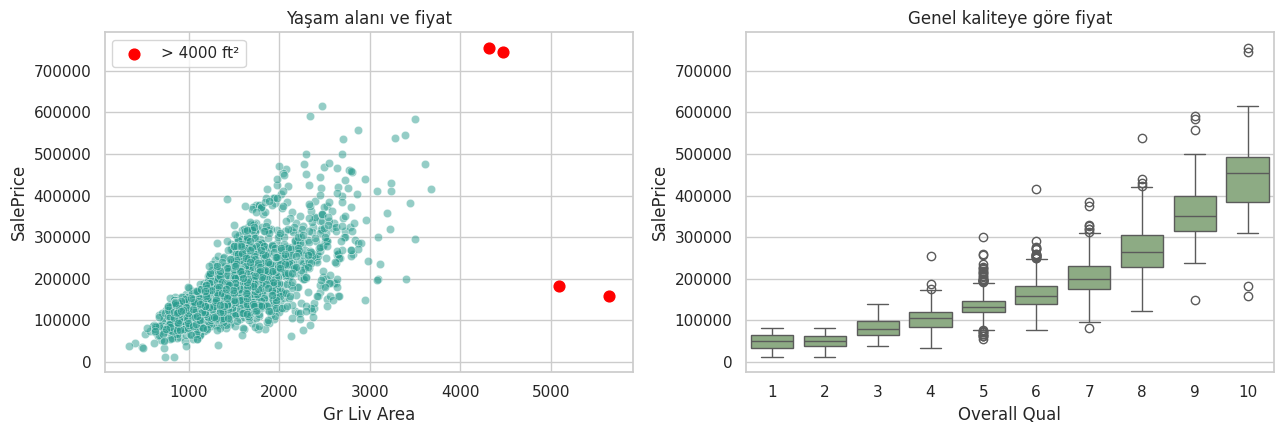

,Gr Liv Area,SalePrice,Overall Qual,Sale Condition
391,5642,160000,10,Partial
451,4476,745000,10,Abnorml
915,4316,755000,10,Normal
1634,5095,183850,10,Partial


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=train_df, x="Gr Liv Area", y=TARGET, alpha=0.5, ax=ax[0], color="#2a9d8f")
out = train_df[train_df["Gr Liv Area"] > 4000]
ax[0].scatter(out["Gr Liv Area"], out[TARGET], color="red", s=60, label="> 4000 ft²")
ax[0].legend(); ax[0].set_title("Yaşam alanı ve fiyat")
sns.boxplot(data=train_df, x="Overall Qual", y=TARGET, ax=ax[1], color="#8ab17d")
ax[1].set_title("Genel kaliteye göre fiyat")
plt.tight_layout(); plt.show()

display(out[["Gr Liv Area", TARGET, "Overall Qual", "Sale Condition"]])

**Yorum:** Eğitim kümesinde `Gr Liv Area` > 4000 ft² olan yalnızca 4 ev var. Bunların ikisi çok
büyük olmasına rağmen düşük fiyatlı ve ikisi de `Sale Condition = Partial` (yeni inşa, tamamlanmamış
ev satışı); diğer ikisi ise gerçekten çok pahalı (745 bin ve 755 bin dolar). Bu yüzden çıkarma
kararı Adım 2'de, grafikle birlikte ve gerekçesiyle verilecek. Kalite arttıkça fiyatın
hem arttığı hem de dağılımın genişlediği de görülüyor.

### 1.10 Kategorik özellikler

Toplam kategorik sütun: 43 | Toplam kategori düzeyi: 279


,Farklı değer,En sık değerin oranı
Neighborhood,28,0.157
Exterior 1st,16,0.343
Exterior 2nd,16,0.340
Sale Type,10,0.873
Condition 1,9,0.860
House Style,8,0.508
Functional,8,0.931
Roof Matl,8,0.983



Neredeyse sabit (en sık değer > %95) kategorik sütunlar:
Utilities       0.999
Street          0.995
Pool QC         0.995
Condition 2     0.991
Heating         0.983
Roof Matl       0.983
Misc Feature    0.960
Land Slope      0.951


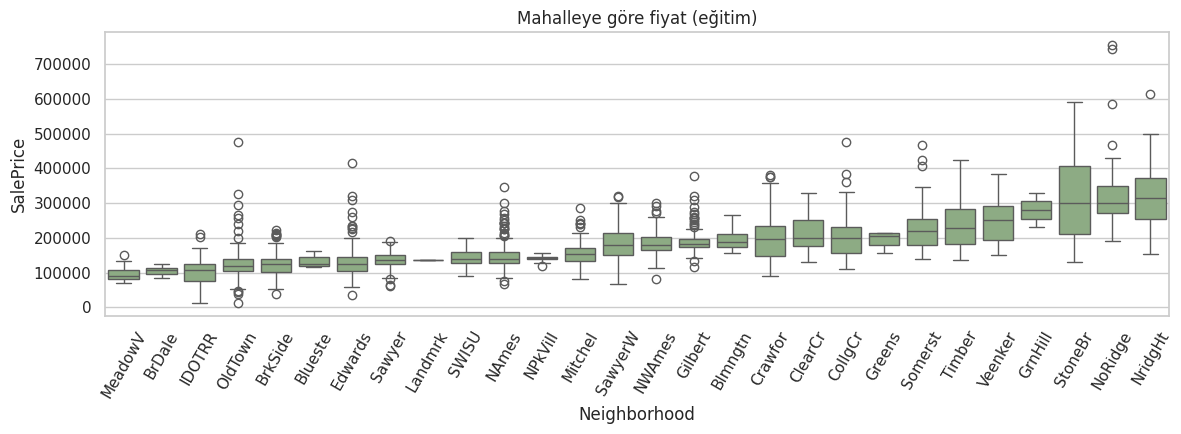

In [11]:
cat_cols = train_df.select_dtypes(exclude="number").columns.tolist()
card = train_df[cat_cols].nunique().sort_values(ascending=False)
dom = pd.Series({c: train_df[c].value_counts(normalize=True).iloc[0] for c in cat_cols})
cat_tbl = pd.DataFrame({"Farklı değer": card, "En sık değerin oranı": dom[card.index].round(3)})
print("Toplam kategorik sütun:", len(cat_cols), "| Toplam kategori düzeyi:", int(card.sum()))
display(cat_tbl.head(8))
print("\nNeredeyse sabit (en sık değer > %95) kategorik sütunlar:")
print(dom[dom > 0.95].round(3).sort_values(ascending=False).to_string())

order = (train_df.groupby("Neighborhood")[TARGET].median().sort_values().index)
plt.figure(figsize=(12, 4.5))
sns.boxplot(data=train_df, x="Neighborhood", y=TARGET, order=order, color="#8ab17d")
plt.xticks(rotation=60); plt.title("Mahalleye göre fiyat (eğitim)")
plt.tight_layout(); plt.show()

**Yorum:** One-Hot kodlama sonrası özellik sayısı yaklaşık 300'e çıkacak. `Street`, `Utilities`,
`Roof Matl`, `Condition 2`, `Heating`, `Pool QC` gibi sütunlarda neredeyse tüm satırlar aynı değeri taşıyor,
bunlar modele neredeyse hiç bilgi katmaz. `Neighborhood` ise fiyatı belirgin şekilde ayırıyor
(mahalle farkı büyük) ve önemli bir özellik olacak.

### 1.11 Bölüm 1 özeti

| Konu | Bulgu |
|---|---|
| Boyut | 2930 satır, 80 sütun (79 özellik + hedef) |
| Eğitim / test | 2344 / 586 (rastgele, `random_state=42`) |
| Hedef | `SalePrice` sağa çarpık (≈1.7), log alınca simetrik (≈0) |
| "Yok" anlamındaki NA | Havuz, çit, şömine, garaj, bodrum sütunlarında. Eksik veri değildir |
| Gerçek eksik | Başlıca `Lot Frontage` (~%17) ve `Garage Yr Blt` |
| En önemli özellikler | `Overall Qual`, `Gr Liv Area`, garaj/bodrum alanı, `Neighborhood` |
| Çoklu bağlantı | Korelasyonu 0.8'in üstünde 4 özellik çifti, Ridge/Lasso gerekçesi |
| Dikkat | 4000 ft² üstü 4 ev (2'si düşük fiyatlı Partial satış), neredeyse sabit 8 kategorik sütun |

**Sonraki adım (Bölüm 2):** veri temizleme ve hazırlama (NA'ların işlenmesi, aykırı değer kararı,
kodlama ve ölçekleme stratejisi).